# Delivery Delay Model

Predicting, at the moment an order is placed, whether it will arrive after the estimated
delivery date. The label is `is_late = order_delivered_customer_date > order_estimated_delivery_date`,
and every input has to be knowable at `order_purchase_timestamp`.

The notebook walks through the decisions that shape the model: which orders are eligible, how
the timeline is cut, what the seller-history features can and cannot see, how the models
compare, where the decision threshold belongs, and what drives the predictions.

In [1]:
from __future__ import annotations

import logging
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')


def notebook_dir() -> Path:
    # __file__ exists when the notebook is executed as a script; otherwise fall back to CWD,
    # which Jupyter/nbconvert sets to the notebook's directory.
    try:
        return Path(__file__).resolve().parent
    except NameError:
        return Path.cwd().resolve()


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'data').is_dir() and (candidate / 'pyproject.toml').is_file():
            return candidate
    raise RuntimeError(f'Could not locate project root (data/ + pyproject.toml) from {start}')


PROJECT_ROOT = find_project_root(notebook_dir())
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ORDER_LEVEL_PATH
from src.features.build_features import ALL_FEATURES, build_modelling_frame
from src.modeling.evaluate import CostMatrix, compute_metrics, threshold_curve
from src.modeling.explain import global_importance, grouped_importance
from src.modeling.models import build_model
from src.modeling.splitting import chronological_split, load_model_config, temporal_cv_splits

logging.getLogger('src').setLevel(logging.WARNING)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

config = load_model_config()
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'seed         = {config["seed"]}')


PROJECT_ROOT = D:\reps\olist-intelligence
seed         = 42


## The labelled population

Only delivered orders with both timestamps present carry a label. That is 96,470 of 99,441
orders, and 8.11% of them are late — a 1:11 imbalance that shapes every metric choice below.

In [2]:
orders = pd.read_parquet(ORDER_LEVEL_PATH)
frame = build_modelling_frame(orders)

print(f"orders in the analytical dataset : {len(orders):,}")
print(f"orders with a usable label       : {len(frame):,}")
print(f"late orders                      : {int(frame['is_late'].sum()):,}")
print(f"late rate                        : {frame['is_late'].mean():.2%}")
print(f"imbalance                        : 1 : {(1 - frame['is_late'].mean()) / frame['is_late'].mean():.1f}")

orders in the analytical dataset : 99,441
orders with a usable label       : 96,470
late orders                      : 7,826
late rate                        : 8.11%
imbalance                        : 1 : 11.3


## Cutting the timeline

The model is trained on the past and applied to the future, so the split is three contiguous
windows of purchase dates. 2016 is excluded — it holds 329 orders in total — and the window
ends in August 2018, because September and October hold 20 orders between them.

The late rate is not stable across the window, which is the single most important fact about
this dataset for modelling purposes.

In [3]:
split = chronological_split(frame)
split.summary

,partition,orders,late,late_rate,purchase_from,purchase_to
0,train,64053,5886,0.091893,2017-01-05 11:56:06,2018-03-31 23:54:10
1,validation,13547,917,0.067690,2018-04-01 00:11:32,2018-05-31 23:51:24
2,test,18603,1019,0.054776,2018-06-01 00:39:55,2018-08-29 15:00:37


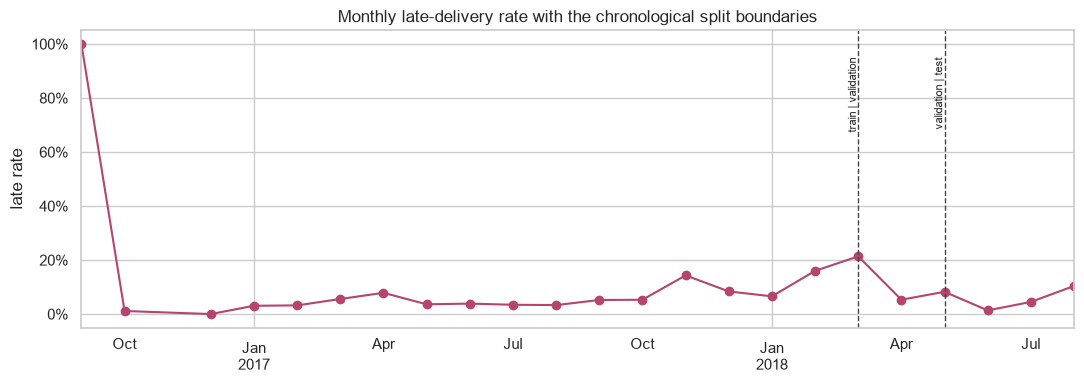

,orders,late,late_rate
month,,,
2016-09,1,1,100.0%
2016-10,265,3,1.1%
2016-12,1,0,0.0%
2017-01,750,23,3.1%
2017-02,1653,53,3.2%
2017-03,2546,142,5.6%
2017-04,2303,181,7.9%
2017-05,3545,128,3.6%
2017-06,3135,121,3.9%


In [4]:
monthly = (
    frame.assign(month=frame["order_purchase_timestamp"].dt.to_period("M"))
    .groupby("month")
    .agg(orders=("is_late", "size"), late=("is_late", "sum"))
)
monthly["late_rate"] = monthly["late"] / monthly["orders"]

fig, ax = plt.subplots(figsize=(11, 4))
monthly["late_rate"].plot(ax=ax, marker="o", color="#b5446e")
for boundary, label in [
    (split.windows.train_end, "train | validation"),
    (split.windows.validation_end, "validation | test"),
]:
    ax.axvline(pd.Period(boundary, "M"), color="#444", linestyle="--", linewidth=1)
    ax.annotate(label, xy=(pd.Period(boundary, "M"), monthly["late_rate"].max() * 0.95),
                rotation=90, fontsize=8, ha="right", va="top")
ax.set_title("Monthly late-delivery rate with the chronological split boundaries")
ax.set_ylabel("late rate")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

monthly.assign(late_rate=monthly["late_rate"].map("{:.1%}".format))

Three months stand out: November 2017 (14.3%), February 2018 (16.0%) and March 2018 (21.4%)
against a 3–5% baseline, and June 2018 collapses to 1.4%. November coincides with a 63% volume
jump, so a capacity failure is plausible; March has ordinary volume, so it is not. Whatever the
cause, a model that learns "March means late" will be wrong the following March. This is why
the tree ensembles below are kept shallow and heavily regularised — they are the models capable
of memorising those spikes, and they generalise worse for it.

## Seller history without looking ahead

A seller's past delivery record is the most obviously useful feature and the easiest one to
leak. The subtlety is *when* a past order becomes knowledge: not when it was purchased, but
when it was delivered. An order placed in January and delivered in March tells you nothing in
February.

So the features merge on the completion timeline: for each order, they summarise the seller's
orders that had already been **delivered** before this one was placed. That definition is
invariant to the future — adding or relabelling later orders cannot change an earlier order's
features — which is what the test suite asserts.

In [5]:
history_cols = [
    "seller_prior_orders",
    "seller_prior_late_rate",
    "seller_prior_mean_delivery_days",
    "seller_has_history",
]
frame[history_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
seller_prior_orders,96470.0,169.068871,282.930189,0.000000,12.000000,51.000000,180.000000,1788.000000
seller_prior_late_rate,91189.0,0.053654,0.073958,0.000000,0.000000,0.038462,0.074423,1.000000
seller_prior_mean_delivery_days,91189.0,11.995141,3.522230,1.196979,9.978973,11.796161,13.751469,70.213611
seller_has_history,96470.0,0.945258,0.227478,0.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
known = frame[frame['seller_has_history'] == 1.0]
print(f'orders with seller history : {len(known):,} of {len(frame):,} ({len(known) / len(frame):.1%})')
print(f'late rate with history     : {known["is_late"].mean():.2%}')
print(f'late rate without history  : {frame[frame["seller_has_history"] == 0.0]["is_late"].mean():.2%}')

bins = pd.cut(known['seller_prior_late_rate'], [0, 0.02, 0.05, 0.10, 0.20, 1.0])
by_history = known.groupby(bins, observed=True).agg(
    orders=('is_late', 'size'), late_rate=('is_late', 'mean')
)
by_history['late_rate'] = by_history['late_rate'].map('{:.2%}'.format)
by_history


orders with seller history : 91,189 of 96,470 (94.5%)
late rate with history     : 8.17%
late rate without history  : 7.18%


,orders,late_rate
seller_prior_late_rate,,
"(0.0, 0.02]",4461,6.61%
"(0.02, 0.05]",22549,7.62%
"(0.05, 0.1]",22599,10.00%
"(0.1, 0.2]",11303,8.58%
"(0.2, 1.0]",2668,11.13%


The relationship is real but not clean: the late rate rises from 6.6% for sellers whose
completed orders were almost never late to 11.1% for the worst group, but the 0.10-0.20 bucket
dips to 8.6% rather than continuing upward. The signal is a gradient, not a rule — which is
exactly what a model should be given, and exactly why it should not be read as a per-seller
verdict.

## Temporal cross-validation

Hyperparameters are searched on expanding-window folds **inside** the training window, with a
30-day purge gap at each boundary. Without the gap, an order purchased on the last day of a fit
window is typically delivered after the next fold begins, so its label would be visible to a
model that is supposed to be predicting it.

In [7]:
folds = temporal_cv_splits(
    split.train,
    n_splits=config["cv"]["n_splits"],
    purge_days=config["cv"]["purge_days"],
)

fold_table = pd.DataFrame(
    [
        {
            "fold": i,
            "fit_orders": len(fit),
            "fit_until": split.train.iloc[fit]["order_purchase_timestamp"].max().date(),
            "eval_orders": len(eval_idx),
            "eval_from": split.train.iloc[eval_idx]["order_purchase_timestamp"].min().date(),
            "eval_to": split.train.iloc[eval_idx]["order_purchase_timestamp"].max().date(),
        }
        for i, (fit, eval_idx) in enumerate(folds)
    ]
)
fold_table

,fold,fit_orders,fit_until,eval_orders,eval_from,eval_to
0,0,7693,2017-05-04,9053,2017-06-04,2017-08-17
1,1,16181,2017-07-18,10441,2017-08-18,2017-10-31
2,2,26271,2017-10-01,15880,2017-11-01,2018-01-14
3,3,41358,2017-12-15,17384,2018-01-15,2018-03-30


## Model comparison

Five candidates, from a prior-only baseline to two gradient-boosted ensembles. Each is scored
on validation at **its own cost-optimal threshold**, because a class-weighted model and a
calibrated one put their useful operating point in completely different places — comparing them
at a fixed 0.5 would rank them by calibration rather than by skill. PR-AUC and ROC-AUC are
threshold-free and unaffected.

In [8]:
from src.modeling.train import evaluate_pipeline

cost = CostMatrix(**config["cost"])
X_train, y_train = split.train[list(ALL_FEATURES)], split.train["is_late"]

results = {}
fitted = {}
for name in ["dummy", "logistic_regression", "random_forest", "lightgbm", "xgboost"]:
    pipeline = build_model(name, config).fit(X_train, y_train)
    fitted[name] = pipeline
    results[name] = evaluate_pipeline(pipeline, split.validation, cost=cost)

comparison = pd.DataFrame(results).T
comparison[["pr_auc", "roc_auc", "precision", "recall", "f1", "threshold", "cost_per_order"]]

,pr_auc,roc_auc,precision,recall,f1,threshold,cost_per_order
dummy,0.067690,0.500000,0.000000,0.000000,0.000000,0.10,0.676903
logistic_regression,0.184272,0.750758,0.173064,0.550709,0.263364,0.15,0.482247
random_forest,0.145315,0.694464,0.134475,0.522356,0.213887,0.10,0.550897
lightgbm,0.174370,0.684454,0.137476,0.465649,0.212279,0.11,0.559460
xgboost,0.174706,0.689402,0.141009,0.463468,0.216230,0.11,0.554292


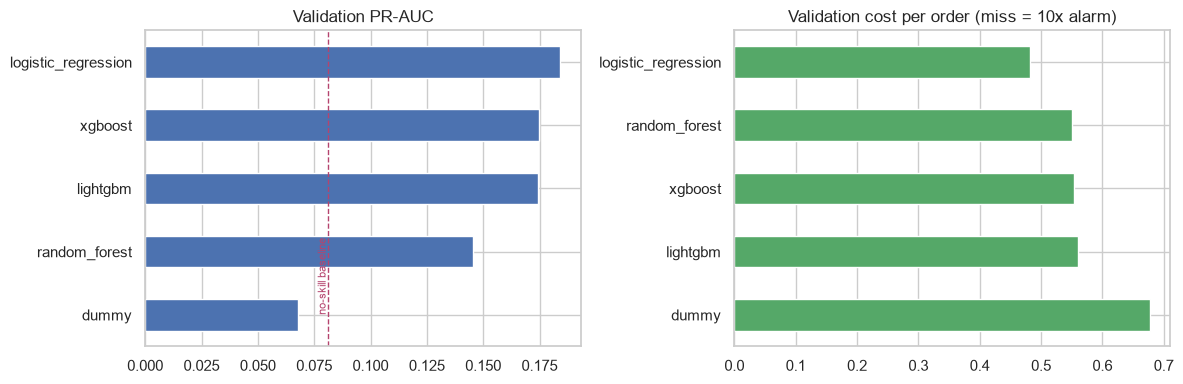

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

comparison["pr_auc"].sort_values().plot.barh(ax=axes[0], color="#4c72b0")
axes[0].axvline(frame["is_late"].mean(), color="#b5446e", linestyle="--", linewidth=1)
axes[0].annotate("no-skill baseline", xy=(frame["is_late"].mean(), 0), rotation=90,
                 fontsize=8, ha="right", va="bottom", color="#b5446e")
axes[0].set_title("Validation PR-AUC")
axes[0].set_xlabel("")

comparison["cost_per_order"].sort_values(ascending=False).plot.barh(ax=axes[1], color="#55a868")
axes[1].set_title("Validation cost per order (miss = 10x alarm)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

The regularised linear model wins on both ranking metrics. That is not an accident of tuning:
the signal here is close to additive — a longer estimated lead time, a cross-state route, a
distant seller, a state with poor infrastructure — and a linear model in a one-hot space
represents exactly that. The ensembles have the capacity to memorise the 2017-11 and 2018-03
spikes, and they do, at the cost of generalisation.

## Where the threshold belongs

A probability is not a decision. The threshold is chosen on validation by minimising an
explicit cost: a missed late order costs ten times an unnecessary alarm. The curve below shows
why the choice matters more than the model.

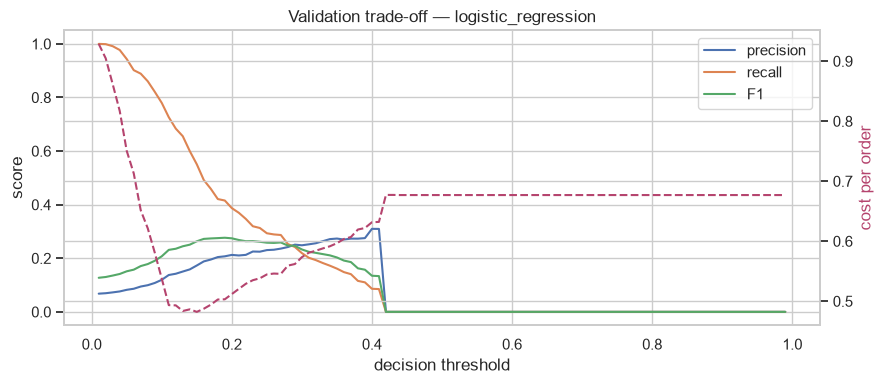

In [10]:
best_name = comparison["pr_auc"].idxmax()
best = fitted[best_name]
val_proba = best.predict_proba(split.validation[list(ALL_FEATURES)])[:, 1]
curve = threshold_curve(split.validation["is_late"].to_numpy(), val_proba, cost=cost)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve["threshold"], curve["precision"], label="precision")
ax.plot(curve["threshold"], curve["recall"], label="recall")
ax.plot(curve["threshold"], curve["f1"], label="F1")
ax2 = ax.twinx()
ax2.plot(curve["threshold"], curve["cost_per_order"], color="#b5446e", linestyle="--", label="cost / order")
ax2.set_ylabel("cost per order", color="#b5446e")
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title(f"Validation trade-off — {best_name}")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [11]:
from src.modeling.evaluate import cost_sensitivity

cost_sensitivity(split.validation["is_late"].to_numpy(), val_proba)

,cost_ratio,threshold,precision,recall,f1,cost_per_order
0,1.0,0.44,0.000000,0.000000,0.000000,0.067690
1,2.0,0.44,0.000000,0.000000,0.000000,0.135381
2,5.0,0.27,0.236086,0.286805,0.258986,0.304200
3,10.0,0.15,0.173064,0.550709,0.263364,0.482247
4,20.0,0.11,0.137575,0.726281,0.231330,0.678748
5,50.0,0.04,0.076236,0.977099,0.141436,0.878940


The threshold is not a property of the model — it is a statement about the business. If a
missed late order costs fifty times an alarm rather than ten, the operating point moves from
flagging roughly half the late orders to flagging almost all of them, at the price of a much
larger false-positive load. That is a decision for whoever acts on the flag, not for the model.

## What drives the predictions

SHAP contributions, grouped back from the one-hot columns to the source features.

Background dataset has 2000 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=2000 when initializing the masker.


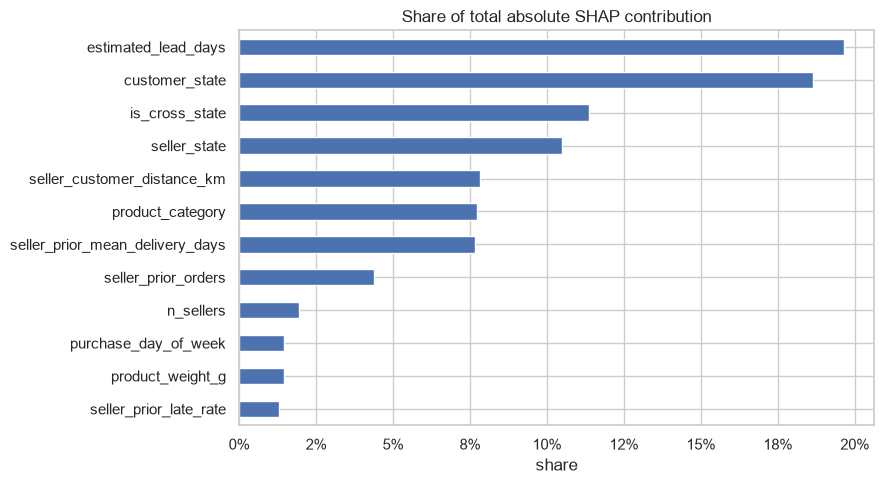

,group,mean_abs_shap,share
0,estimated_lead_days,0.626635,19.6%
1,customer_state,0.595245,18.7%
2,is_cross_state,0.362682,11.4%
3,seller_state,0.334726,10.5%
4,seller_customer_distance_km,0.249802,7.8%
5,product_category,0.246569,7.7%
6,seller_prior_mean_delivery_days,0.244486,7.7%
7,seller_prior_orders,0.139635,4.4%
8,n_sellers,0.062261,2.0%
9,purchase_day_of_week,0.046936,1.5%


In [12]:
importance = global_importance(best, split.validation[list(ALL_FEATURES)], max_rows=2000)
grouped = grouped_importance(importance)

fig, ax = plt.subplots(figsize=(9, 5))
grouped.head(12).iloc[::-1].plot.barh(x="group", y="share", ax=ax, color="#4c72b0", legend=False)
ax.set_title("Share of total absolute SHAP contribution")
ax.set_xlabel("share")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

grouped.head(12).assign(share=lambda d: d["share"].map("{:.1%}".format))

The estimated lead time is the largest single driver at 19.6%, which is the right answer: it is
the promise the order is measured against, and a generous estimate is easy to beat. Geography
follows — customer state (18.7%), the cross-state flag (11.4%), seller state (10.5%) and the
seller-to-customer distance (7.8%) — and the seller's own delivery record contributes 7.7% plus
4.4% for its order count. All of it is known at checkout.

One caveat on reading these shares: the categorical blocks are split across many one-hot
columns, so a state's contribution is spread over 27 columns while a numeric feature is a single
column. Summing the group is the right way to compare them, which is what the table does.

## The test window

Scored once, with the threshold frozen from validation. The late rate in this window is 5.5%,
lower than the 9.2% the model was trained on, so the absolute numbers are worse than validation
by construction — a model cannot know that June 2018 would be unusually punctual.

In [13]:
threshold = comparison.loc[best_name, "threshold"]
test_proba = best.predict_proba(split.test[list(ALL_FEATURES)])[:, 1]
test_metrics = compute_metrics(split.test["is_late"].to_numpy(), test_proba, threshold=threshold, cost=cost)

pd.Series(test_metrics).to_frame("value").round(4)

,value
roc_auc,0.6879
pr_auc,0.0986
precision,0.0991
recall,0.4691
f1,0.1636
accuracy,0.7373
threshold,0.1500
tn,13238.0000
fp,4346.0000
fn,541.0000


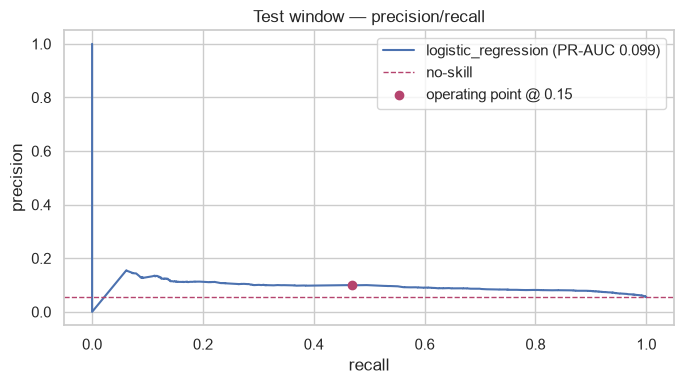

In [14]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(split.test["is_late"], test_proba)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall, precision, color="#4c72b0", label=f"{best_name} (PR-AUC {test_metrics['pr_auc']:.3f})")
ax.axhline(split.test["is_late"].mean(), color="#b5446e", linestyle="--", linewidth=1, label="no-skill")
ax.scatter([test_metrics["recall"]], [test_metrics["precision"]], color="#b5446e", zorder=5,
           label=f"operating point @ {threshold:.2f}")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Test window — precision/recall")
ax.legend()
plt.tight_layout()
plt.show()

## Reading the result honestly

A PR-AUC of 0.10 against a 0.055 base rate means the model concentrates late orders about
1.8 times better than chance. That is a real but modest lift, and it is worth being precise
about what it does and does not support.

**What it supports.** Ranking orders by risk. At the chosen threshold the model catches roughly
half the late orders while flagging a fifth of the book — enough to prioritise a support queue
or a proactive-contact list, where the alternative is treating every order identically.

**What it does not support.** Per-order certainty. A 0.15 probability is not "this will be
late"; it is "orders like this are late about three times as often as the average order".

**Why the ceiling is where it is.** The label is a comparison against a *promise*, not against
a physical delivery time. The estimate is generated by a process the dataset does not expose,
and it moves: the same route that was late in March 2018 was punctual in June. No feature
available at checkout can see a change in how the estimate is set. That is the dominant source
of irreducible error here, and it is why the linear model's simplicity is an advantage rather
than a limitation.